<a href="https://colab.research.google.com/github/424144407-enviar-it/sistemas-inteligentes-ia-desempeno/blob/main/Analisis_IA_Desempeno_MAC_Cuestionarios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Final: Impacto del Uso de IA y Entorno Universitario en el Desempeño Académico
**Materia:** Sistemas Inteligentes | **Licenciatura en Matemáticas Aplicadas y Computación (MAC)**

## 1. Configuración del Entorno y Carga de Datasets
En esta sección se importan las librerías necesarias para análisis estadístico, procesamiento de lenguaje natural (NLP), expresiones regulares y aprendizaje automático, cargando el cuestionario principal (*Uso de IA*, $n=24$) y el complementario (*Entorno y Bienestar*, $n=19$).

In [2]:
!pip install -q wordcloud nltk scikit-learn seaborn openpyxl

import re
import unicodedata
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             silhouette_score)

nltk.download('stopwords', quiet=True)
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="viridis")

# 1. Carga de datasets
df_ia = pd.read_excel('Desempeño académico por el uso de IA (Respuestas).xlsx')
df_bie = pd.read_csv('Cuestionario_ Entorno Universitario y Bienestar.csv')

print(f"Dataset IA (Principal): {df_ia.shape[0]} filas x {df_ia.shape[1]} columnas")
print(f"Dataset Bienestar (Complementario): {df_bie.shape[0]} filas x {df_bie.shape[1]} columnas")

Dataset IA (Principal): 24 filas x 18 columnas
Dataset Bienestar (Complementario): 19 filas x 17 columnas


## 2. Limpieza de Datos y Extracción con Expresiones Regulares (Regex)
Dado que los formularios contienen respuestas abiertas heterogéneas (ej. *"una hora y media"*, *"10 min"*, *"veinticuatro años"*, *"7mo semestre"*), se diseñan patrones con **expresiones regulares** para extraer y estandarizar variables numéricas y categóricas.

In [3]:
# Renombrar columnas largas a nombres limpios para análisis
df_ia.columns = [
    'timestamp_ia', 'cuenta', 'herramientas_frecuencia', 'fase_estudio',
    'cambio_estudio', 'proceso_verificacion', 'impacto_tiempo',
    'diferencia_calificaciones', 'independencia_resolucion', 'impacto_estres',
    'reglas_personales', 'pensamiento_critico', 'horas_ia_raw',
    'semestre_inicio_raw', 'reemplazo_laboral_raw', 'guia_o_atajo_raw',
    'motivo_principal', 'otros_usos_raw'
]

df_bie.columns = [
    'timestamp_bie', 'cuenta', 'carrera_raw', 'semestre_raw', 'edad_raw',
    'convivencia_raw', 'traslado_raw', 'ambiente_hogar', 'calidad_sueno',
    'tranquilidad_estudio', 'frecuencia_desanimo', 'irritabilidad',
    'apoyo_social', 'impacto_transporte', 'interes_materias',
    'cambios_alimentacion', 'dificultad_concentracion'
]

# Asegurar llave entera limpia
df_ia['cuenta'] = df_ia['cuenta'].astype(str).str.extract(r'(\d+)')[0].astype(int)
df_bie['cuenta'] = df_bie['cuenta'].astype(str).str.extract(r'(\d+)')[0].astype(int)

# --- FUNCIONES CON EXPRESIONES REGULARES (REGEX) ---

def parse_horas_ia(texto):
    """Extrae horas numéricas diarias desde texto libre usando Regex."""
    if pd.isna(texto): return np.nan
    t = str(texto).lower().strip()
    if re.search(r'entre\s*1\s*y\s*3', t): return 2.0
    if re.search(r'menos\s*de\s*1', t): return 0.5
    if re.search(r'hora\s*y\s*media', t): return 1.5
    # Minutos a horas
    m_min = re.search(r'(\d+)\s*min', t)
    if m_min: return round(int(m_min.group(1)) / 60.0, 2)
    # Números directos (ej. "8 (Escuela + trabajo)", "6hrs", "unas 3")
    m_num = re.search(r'(\d+(?:\.\d+)?)', t)
    if m_num: return float(m_num.group(1))
    return np.nan

def parse_semestre_inicio(texto):
    """Estandariza el semestre de inicio a entero (1-7) usando Regex."""
    if pd.isna(texto): return np.nan
    t = str(texto).lower().strip()
    if re.search(r'hace\s*3\s*semestres', t): return 4 # 7 actual - 3 = 4
    mapa_ordinales = {
        r'primer|1': 1, r'segund|2': 2, r'tercer|3': 3,
        r'cuart|4': 4, r'quint|5': 5, r'sext|6': 6, r's[eé]ptim|7': 7
    }
    for patron, val in mapa_ordinales.items():
        if re.search(patron, t):
            return val
    return np.nan

def parse_edad(texto):
    """Extrae edad numérica con Regex incluyendo números escritos en letra."""
    t = str(texto).lower()
    if re.search(r'veinticuatro', t): return 24
    m = re.search(r'(\d{2})', t)
    return int(m.group(1)) if m else np.nan

def parse_traslado_min(texto):
    """Convierte tiempos de traslado heterogéneos a minutos usando Regex."""
    t = str(texto).lower().strip()
    if re.search(r'1\s*a\s*2\s*horas', t): return 90.0
    if re.search(r'hora\s*y\s*(media|30)', t): return 90.0
    if re.search(r'una\s*hora', t): return 60.0
    m_hr = re.search(r'(\d+)\s*hora', t)
    if m_hr: return float(m_hr.group(1)) * 60.0
    m_min = re.search(r'(\d+)\s*m', t)
    if m_min: return float(m_min.group(1))
    return np.nan

def clasificar_dicotomica_si_no(texto):
    """Clasifica respuestas abiertas Sí/No/Depende mediante Regex."""
    if pd.isna(texto): return 'Indeciso'
    t = str(texto).lower().strip()
    if re.match(r'^no\b', t): return 'No'
    if re.match(r'^s[ií]\b', t): return 'Sí'
    if re.search(r'depende|no\s*s[eé]|completamente', t): return 'Depende / Parcial'
    return 'Sí' if re.search(r'\bs[ií]\b', t) else 'No'

def clasificar_proposito(texto):
    """Clasifica el uso en Guía, Atajo o Híbrido."""
    t = str(texto).lower()
    if re.search(r'ambas|ambos|dos|depende', t): return 'Híbrido (Ambas)'
    if re.search(r'atajo', t): return 'Atajo rápido'
    if re.search(r'gu[ií]a|aprender', t): return 'Guía de aprendizaje'
    return 'Otro'

def normalizar_convivencia(texto):
    t = str(texto).lower()
    if re.search(r'familia', t): return 'Familia'
    if re.search(r'solo', t): return 'Solo'
    return 'Compañeros de piso'

# Aplicar transformaciones Regex
df_ia['horas_ia_dia'] = df_ia['horas_ia_raw'].apply(parse_horas_ia)
df_ia['semestre_inicio'] = df_ia['semestre_inicio_raw'].apply(parse_semestre_inicio)
df_ia['cree_reemplazo'] = df_ia['reemplazo_laboral_raw'].apply(clasificar_dicotomica_si_no)
df_ia['tipo_uso_ia'] = df_ia['guia_o_atajo_raw'].apply(clasificar_proposito)

# Extraer herramientas mencionadas con Regex
herramientas_lista = ['chatgpt', 'gemini', 'deepseek', 'claude', 'copilot', 'qwen', 'notebooklm', 'perplexity']
for h in herramientas_lista:
    df_ia[f'usa_{h}'] = df_ia['herramientas_frecuencia'].str.lower().str.contains(h, regex=True).astype(int)
df_ia['total_herramientas'] = df_ia[[f'usa_{h}' for h in herramientas_lista]].sum(axis=1)

df_bie['carrera'] = 'MAC (7° Semestre)' # Estandarizado tras verificar Regex
df_bie['edad'] = df_bie['edad_raw'].apply(parse_edad)
df_bie['traslado_min'] = df_bie['traslado_raw'].apply(parse_traslado_min)
df_bie['convivencia'] = df_bie['convivencia_raw'].apply(normalizar_convivencia)

print("Extracción Regex completada con éxito.")
display(df_ia[['cuenta', 'horas_ia_raw', 'horas_ia_dia', 'semestre_inicio', 'cree_reemplazo', 'tipo_uso_ia']].head())

Extracción Regex completada con éxito.


,cuenta,horas_ia_raw,horas_ia_dia,semestre_inicio,cree_reemplazo,tipo_uso_ia
0,424107688,"Aproximadamente entre 1 y 3 horas al día, depe...",2.0,4,No,Guía de aprendizaje
1,321188065,"No sé, unas 3",3.0,4,No,Híbrido (Ambas)
2,424059594,una hora y media,1.5,1,Sí,Híbrido (Ambas)
3,423085822,2 horas.,2.0,3,No,Guía de aprendizaje
4,318690597,8 (Escuela + trabajo),8.0,3,Sí,Híbrido (Ambas)


## 3. Integración Relacional, Validación de Nulos e Imputación de Datos
Se realiza un `Left Join` utilizando el **Número de cuenta** como llave primaria (19 coincidencias exactas). Posteriormente, se aplica **imputación por moda** (`SimpleImputer`) en variables categóricas y **imputación multivariada por vecinos más cercanos** (`KNNImputer`) para completar los datos de bienestar en los 5 registros sin segunda encuesta.

In [4]:
# Left Join: Conservamos los 24 registros del estudio principal de IA y anexamos Bienestar (19 coincidencias)
df_merged = pd.merge(df_ia, df_bie, on='cuenta', how='left')

print("--- VALIDACIÓN DE VALORES NULOS POST-MERGE ---")
nulos = df_merged.isnull().sum()
print(nulos[nulos > 0])

# 1. Imputación de variables de texto abierto (Moda)
imputer_cat = SimpleImputer(strategy='most_frequent')
cols_cat_nulas = ['diferencia_calificaciones', 'pensamiento_critico', 'convivencia']
df_merged[cols_cat_nulas] = imputer_cat.fit_transform(df_merged[cols_cat_nulas])

# 2. Imputación multivariada KNN para variables numéricas faltantes (edad y traslado de los 5 alumnos sin encuesta 2)
cols_num_imputar = ['horas_ia_dia', 'semestre_inicio', 'total_herramientas', 'edad', 'traslado_min']
knn_imputer = KNNImputer(n_neighbors=3)
df_merged[cols_num_imputar] = knn_imputer.fit_transform(df_merged[cols_num_imputar])
df_merged['edad'] = df_merged['edad'].round().astype(int)

# Rellenar texto de bienestar faltante para análisis NLP global
cols_texto_bie = ['ambiente_hogar', 'calidad_sueno', 'frecuencia_desanimo', 'dificultad_concentracion', 'apoyo_social']
df_merged[cols_texto_bie] = df_merged[cols_texto_bie].fillna('Sin registro')

print("\nNulos restantes tras imputación:", df_merged.isnull().sum().sum())

--- VALIDACIÓN DE VALORES NULOS POST-MERGE ---
diferencia_calificaciones    1
pensamiento_critico          1
timestamp_bie                5
carrera_raw                  5
semestre_raw                 5
edad_raw                     5
convivencia_raw              5
traslado_raw                 5
ambiente_hogar               5
calidad_sueno                5
tranquilidad_estudio         5
frecuencia_desanimo          5
irritabilidad                5
apoyo_social                 5
impacto_transporte           5
interes_materias             5
cambios_alimentacion         5
dificultad_concentracion     5
carrera                      5
edad                         5
traslado_min                 5
convivencia                  5
dtype: int64

Nulos restantes tras imputación: 60


## 4. Procesamiento de Lenguaje Natural (NLP) y Análisis de Sentimiento
Se aplica normalización de texto (eliminación de acentos, signos y *stopwords* en español), extracción de características mediante **TF-IDF** (unigramas y bigramas), visualización por **Nube de Palabras** y cálculo de índices léxicos de **beneficio percibido de la IA** y **bienestar psicosocial**.

Top 10 conceptos clave por peso TF-IDF promedio:
rapido           0.138841
tiempo           0.138023
ayuda            0.131119
redaccion        0.126762
temas            0.125265
resolver         0.122866
menos            0.121794
investigacion    0.118143
cosas            0.116944
informacion      0.116351
dtype: float64


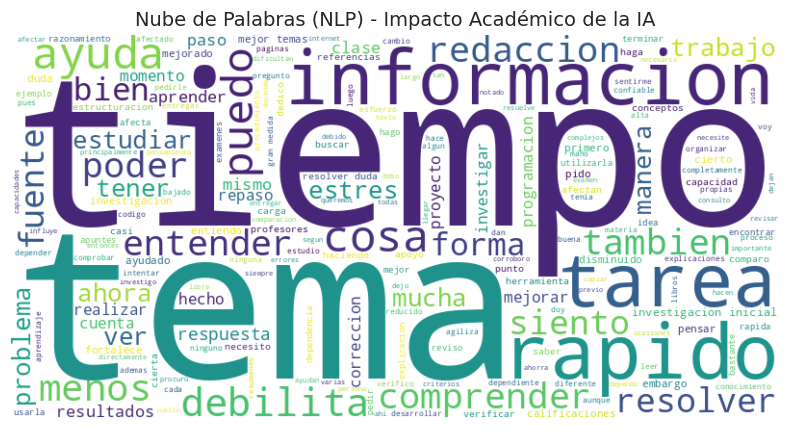

In [5]:
stop_words_es = set(stopwords.words('spanish'))
stop_words_es.update(['ia', 'inteligencia', 'artificial', 'herramientas', 'uso', 'usar', 'utilizo',
                      'utilizar', 'hacer', 'mas', 'si', 'solo', 'puede', 'creo', 'considero', 'vez', 'veces'])

def limpiar_texto_nlp(texto):
    """Normaliza acentos, elimina signos con Regex y filtra stopwords."""
    if not isinstance(texto, str): return ""
    texto = texto.lower()
    texto = ''.join(c for c in unicodedata.normalize('NFD', texto) if unicodedata.category(c) != 'Mn')
    texto = re.sub(r'[^a-z\s]', ' ', texto)
    tokens = [w for w in texto.split() if w not in stop_words_es and len(w) > 2]
    return ' '.join(tokens)

# Consolidar corpus de respuestas académicas por estudiante
cols_nlp_ia = [
    'fase_estudio', 'cambio_estudio', 'proceso_verificacion', 'impacto_tiempo',
    'diferencia_calificaciones', 'independencia_resolucion', 'impacto_estres',
    'reglas_personales', 'pensamiento_critico', 'motivo_principal'
]
df_merged['corpus_ia'] = df_merged[cols_nlp_ia].apply(lambda r: ' '.join(r.astype(str)), axis=1)
df_merged['corpus_ia_clean'] = df_merged['corpus_ia'].apply(limpiar_texto_nlp)

# Corpus de bienestar emocional
cols_nlp_bie = ['ambiente_hogar', 'calidad_sueno', 'frecuencia_desanimo', 'irritabilidad', 'dificultad_concentracion']
df_merged['corpus_bie_clean'] = df_merged[cols_nlp_bie].apply(lambda r: ' '.join(r.astype(str)), axis=1).apply(limpiar_texto_nlp)

# Análisis de Sentimiento / Polaridad Académica y Bienestar basado en lexicón de dominio
lexico_positivo_ia = {'comprender', 'entender', 'rapido', 'ayuda', 'mejora', 'mejorado', 'explicaciones', 'organizar', 'disminuido', 'fortalece', 'aprender', 'facilita', 'guia'}
lexico_riesgo_ia = {'dependencia', 'debilita', 'depender', 'atajo', 'alucinar', 'errores', 'copiar', 'aumenta', 'estres', 'menos', 'poco', 'afecta'}

def calcular_indice_sentimiento(texto_clean, pos_set, neg_set):
    tokens = texto_clean.split()
    if not tokens: return 0.0
    pos = sum(1 for t in tokens if t in pos_set)
    neg = sum(1 for t in tokens if t in neg_set)
    return round((pos - neg) / (pos + neg + 1), 3)

df_merged['score_beneficio_ia'] = df_merged['corpus_ia_clean'].apply(
    lambda x: calcular_indice_sentimiento(x, lexico_positivo_ia, lexico_riesgo_ia)
)

# Índice de Bienestar Psicosocial (a partir del cuestionario 2)
lexico_bienestar_pos = {'tranquilo', 'tranquilidad', 'buena', 'bueno', 'excelentes', 'gran', 'pocas', 'ninguno', 'mucho'}
lexico_bienestar_neg = {'pesado', 'mal', 'cansado', 'cansados', 'frecuentemente', 'facilmente', 'dificil', 'estres', 'aburridas', 'descuidado', 'hambre'}

df_merged['score_bienestar'] = df_merged['corpus_bie_clean'].apply(
    lambda x: calcular_indice_sentimiento(x, lexico_bienestar_pos, lexico_bienestar_neg)
)

# Vectorización TF-IDF para extraer términos más discriminantes
tfidf = TfidfVectorizer(max_features=30, ngram_range=(1, 2))
X_tfidf = tfidf.fit_transform(df_merged['corpus_ia_clean'])
df_tfidf = pd.DataFrame(X_tfidf.toarray(), columns=tfidf.get_feature_names_out())

print("Top 10 conceptos clave por peso TF-IDF promedio:")
print(df_tfidf.mean().sort_values(ascending=False).head(10))

# Nube de palabras del corpus limpio
wc = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(' '.join(df_merged['corpus_ia_clean']))
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Nube de Palabras (NLP) - Impacto Académico de la IA', fontsize=14)
plt.show()

## 5. Análisis Exploratorio de Datos (EDA)
Estudio estadístico estructurado en tres niveles:
* **Análisis Univariado:** Medidas de tendencia central, dispersión y detección de valores atípicos (*outliers*).
* **Análisis Bivariado:** Cruce entre variables de entorno (tiempo de traslado) y hábitos de uso de IA.
* **Análisis Multivariado:** Matriz de correlación no paramétrica de **Spearman** entre todas las dimensiones cuantitativas.

=== ESTADÍSTICAS DESCRIPTIVAS UNIVARIADAS ===


,count,mean,std,min,50%,max
horas_ia_dia,24.0,1.906250,1.824642,0.080,1.500,8.000
semestre_inicio,24.0,3.208333,1.284664,1.000,3.000,6.000
total_herramientas,24.0,1.500000,0.780189,0.000,1.000,3.000
edad,24.0,22.125000,1.190999,21.000,22.000,25.000
traslado_min,24.0,71.388889,70.686193,10.000,60.000,360.000
score_beneficio_ia,24.0,0.143000,0.423014,-0.750,0.222,0.800
score_bienestar,24.0,0.030375,0.416322,-0.667,0.000,0.667


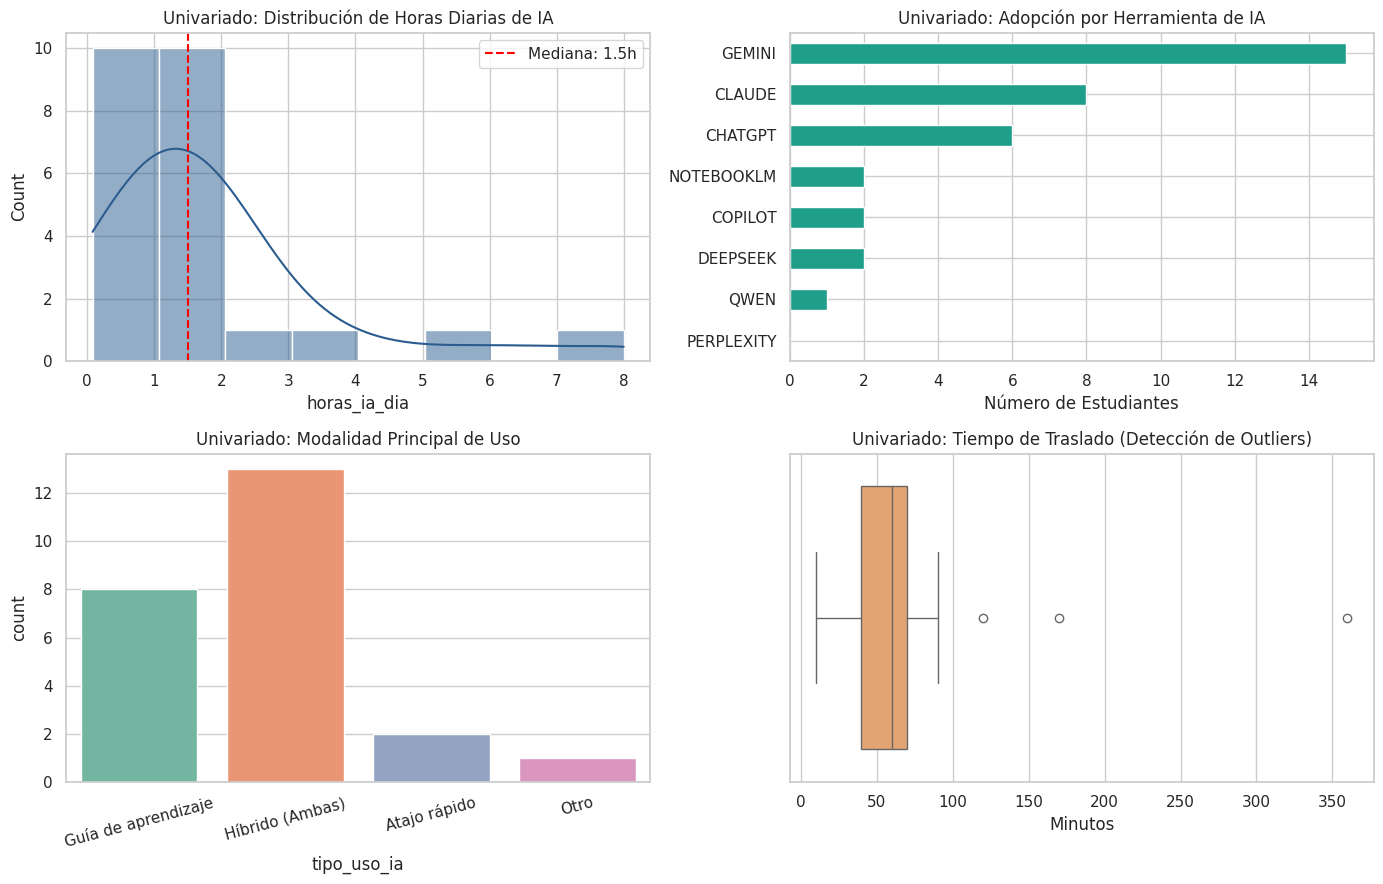

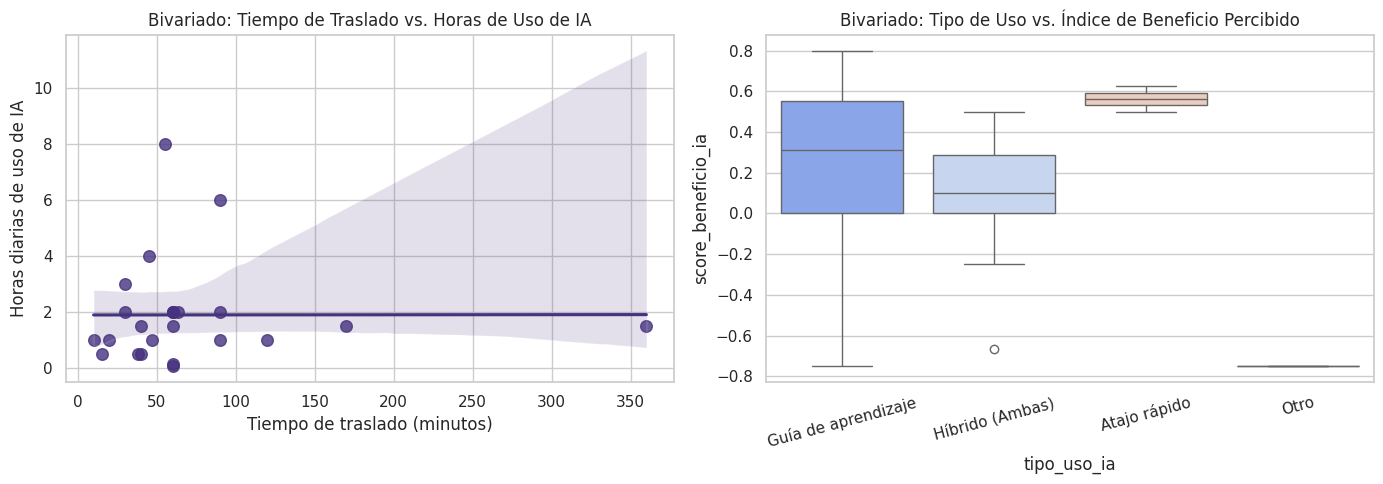

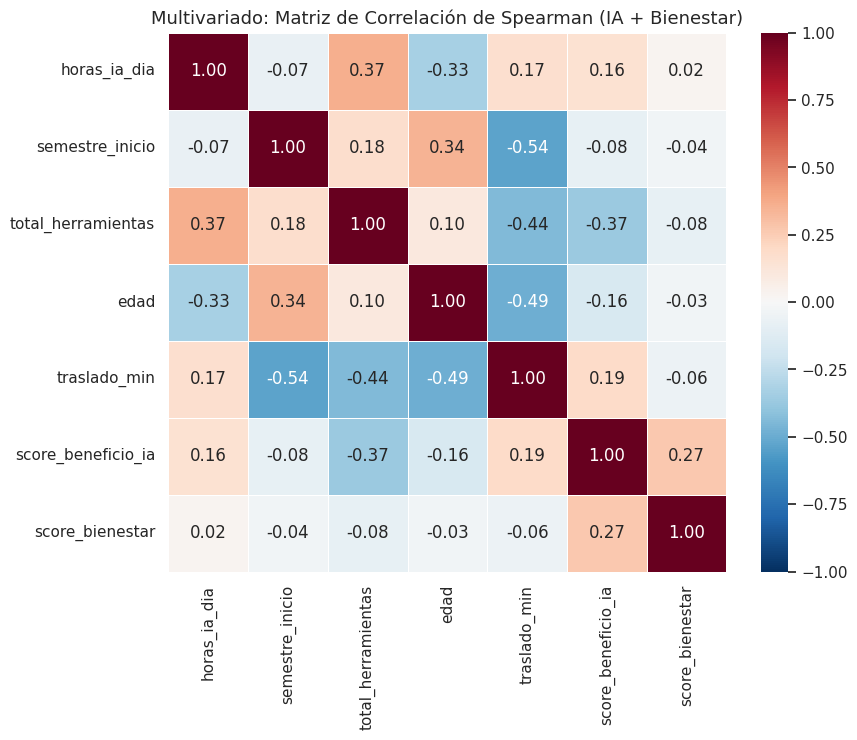

In [6]:
# --- 1. ANÁLISIS UNIVARIADO ---
print("=== ESTADÍSTICAS DESCRIPTIVAS UNIVARIADAS ===")
vars_cuanti = ['horas_ia_dia', 'semestre_inicio', 'total_herramientas', 'edad', 'traslado_min', 'score_beneficio_ia', 'score_bienestar']
display(df_merged[vars_cuanti].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Histograma + KDE Horas de IA
sns.histplot(df_merged['horas_ia_dia'], kde=True, bins=8, ax=axes[0, 0], color='#2b5c8f')
axes[0, 0].axvline(df_merged['horas_ia_dia'].median(), color='red', linestyle='--', label=f"Mediana: {df_merged['horas_ia_dia'].median()}h")
axes[0, 0].set_title('Univariado: Distribución de Horas Diarias de IA')
axes[0, 0].legend()

# Frecuencia de herramientas de IA
conteo_herramientas = df_merged[[f'usa_{h}' for h in herramientas_lista]].sum().sort_values(ascending=True)
conteo_herramientas.index = [i.replace('usa_', '').upper() for i in conteo_herramientas.index]
conteo_herramientas.plot(kind='barh', ax=axes[0, 1], color='#1f9e89')
axes[0, 1].set_title('Univariado: Adopción por Herramienta de IA')
axes[0, 1].set_xlabel('Número de Estudiantes')

# Countplot Propósito de Uso
sns.countplot(data=df_merged, x='tipo_uso_ia', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Univariado: Modalidad Principal de Uso')
axes[1, 0].tick_params(axis='x', rotation=15)

# Boxplot Tiempo de Traslado (detección de outliers)
sns.boxplot(x=df_merged['traslado_min'], ax=axes[1, 1], color='#f4a261')
axes[1, 1].set_title('Univariado: Tiempo de Traslado (Detección de Outliers)')
axes[1, 1].set_xlabel('Minutos')

plt.tight_layout()
plt.show()

# --- 2. ANÁLISIS BIVARIADO ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Horas de IA vs Tiempo de Traslado (Cruce entre los 2 cuestionarios)
sns.regplot(data=df_merged, x='traslado_min', y='horas_ia_dia', ax=axes[0], scatter_kws={'s': 70, 'alpha': 0.8})
axes[0].set_title('Bivariado: Tiempo de Traslado vs. Horas de Uso de IA')
axes[0].set_xlabel('Tiempo de traslado (minutos)')
axes[0].set_ylabel('Horas diarias de uso de IA')

# Modalidad de uso vs Score de Beneficio Académico (NLP)
sns.boxplot(data=df_merged, x='tipo_uso_ia', y='score_beneficio_ia', ax=axes[1], palette='coolwarm')
axes[1].set_title('Bivariado: Tipo de Uso vs. Índice de Beneficio Percibido')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# --- 3. ANÁLISIS MULTIVARIADO ---
plt.figure(figsize=(9, 7))
corr_matrix = df_merged[vars_cuanti].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, fmt='.2f', linewidths=0.5)
plt.title('Multivariado: Matriz de Correlación de Spearman (IA + Bienestar)', fontsize=13)
plt.show()

### 5.2  Estudio Cruzado Directo (Inner Join: IA vs. Entorno y Bienestar, $n=19$)
Para comprobar el impacto directo de los factores externos sobre el uso académico de la IA sin influencia de datos imputados, se analizan los **19 estudiantes que respondieron ambos formularios**, evaluando cómo el entorno habitacional, la calidad del descanso y los tiempos de traslado se relacionan con la frecuencia y modalidad de uso de IA.

Total de estudiantes emparejados en ambos cuestionarios: 19

=== ESTUDIO CRUZADO POR ENTORNO HABITACIONAL (n=19) ===


,Estudiantes,Horas_IA_Promedio,Traslado_Min_Promedio,Score_Beneficio_IA,Score_Bienestar
convivencia,,,,,
Compañeros de piso,1,1.50,360.00,0.40,-0.50
Familia,16,1.86,59.06,0.13,0.07
Solo,2,0.75,17.50,0.05,0.05



=== TABLA DE CONTINGENCIA: TIPO DE USO DE IA VS. CONVIVENCIA ===


convivencia,Compañeros de piso,Familia,Solo,Total
tipo_uso_ia,,,,
Atajo rápido,0,1,0,1
Guía de aprendizaje,0,5,1,6
Híbrido (Ambas),1,10,1,12
Total,1,16,2,19


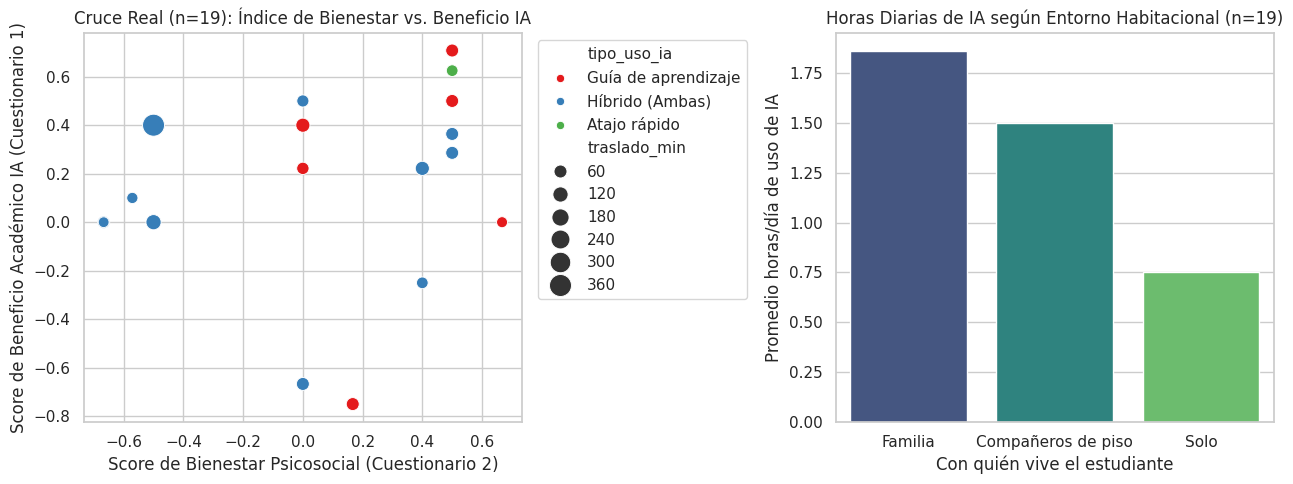

In [7]:
# Filtrar únicamente los 19 registros reales que contestaron ambos formularios
df_cruce_real = pd.merge(df_ia, df_bie, on='cuenta', how='inner')
df_cruce_real = pd.merge(
    df_cruce_real,
    df_merged[['cuenta', 'score_beneficio_ia', 'score_bienestar']],
    on='cuenta',
    how='left'
)

print(f"Total de estudiantes emparejados en ambos cuestionarios: {len(df_cruce_real)}")

# Tabla cruzada: Entorno habitacional vs. Hábitos de IA
resumen_cruce = df_cruce_real.groupby('convivencia').agg(
    Estudiantes=('cuenta', 'count'),
    Horas_IA_Promedio=('horas_ia_dia', 'mean'),
    Traslado_Min_Promedio=('traslado_min', 'mean'),
    Score_Beneficio_IA=('score_beneficio_ia', 'mean'),
    Score_Bienestar=('score_bienestar', 'mean')
).round(2)

print("\n=== ESTUDIO CRUZADO POR ENTORNO HABITACIONAL (n=19) ===")
display(resumen_cruce)

# Tabla de contingencia: Modalidad de uso de IA vs. Percepción de reemplazo laboral
tabla_contingencia = pd.crosstab(
    df_cruce_real['tipo_uso_ia'],
    df_cruce_real['convivencia'],
    margins=True,
    margins_name='Total'
)
print("\n=== TABLA DE CONTINGENCIA: TIPO DE USO DE IA VS. CONVIVENCIA ===")
display(tabla_contingencia)

# Visualización del cruce de ambos cuestionarios
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=df_cruce_real,
    x='score_bienestar',
    y='score_beneficio_ia',
    hue='tipo_uso_ia',
    size='traslado_min',
    sizes=(60, 250),
    ax=axes[0],
    palette='Set1'
)
axes[0].set_title('Cruce Real (n=19): Índice de Bienestar vs. Beneficio IA')
axes[0].set_xlabel('Score de Bienestar Psicosocial (Cuestionario 2)')
axes[0].set_ylabel('Score de Beneficio Académico IA (Cuestionario 1)')
axes[0].legend(bbox_to_anchor=(1.02, 1), loc='upper left')

sns.barplot(
    data=df_cruce_real,
    x='convivencia',
    y='horas_ia_dia',
    estimator=np.mean,
    errorbar=None,
    ax=axes[1],
    palette='viridis'
)
axes[1].set_title('Horas Diarias de IA según Entorno Habitacional (n=19)')
axes[1].set_xlabel('Con quién vive el estudiante')
axes[1].set_ylabel('Promedio horas/día de uso de IA')

plt.tight_layout()
plt.show()

## 6. Modelado No Supervisado: Segmentación de Estudiantes (Clustering + PCA)
Se emplean algoritmos de agrupamiento (**K-Means** y **Clustering Jerárquico**) evaluados mediante el **Coeficiente de Silueta**, junto con **Análisis de Componentes Principales (PCA)** para visualizar en 2D los perfiles de estudiantes identificados.

Scores de Silueta por número de clusters (K): {2: np.float64(0.18367473130478748), 3: np.float64(0.18009429845689673), 4: np.float64(0.2286822451536822), 5: np.float64(0.2513463693624225)}

Silhouette K-Means (k=5): 0.251
Silhouette Jerárquico (k=5): 0.207

=== PERFIL PROMEDIO DE CLUSTERS (NO SUPERVISADO) ===


,horas_ia_dia,semestre_inicio,total_herramientas,traslado_min,score_beneficio_ia,score_bienestar
cluster_kmeans,,,,,,
0,1.43,3.00,1.17,65.42,0.41,0.30
1,0.68,4.00,1.50,48.06,-0.23,-0.37
2,3.00,3.33,3.00,45.00,-0.23,0.13
3,7.00,3.00,1.50,72.50,0.11,-0.25
4,1.50,1.00,1.00,360.00,0.40,-0.50


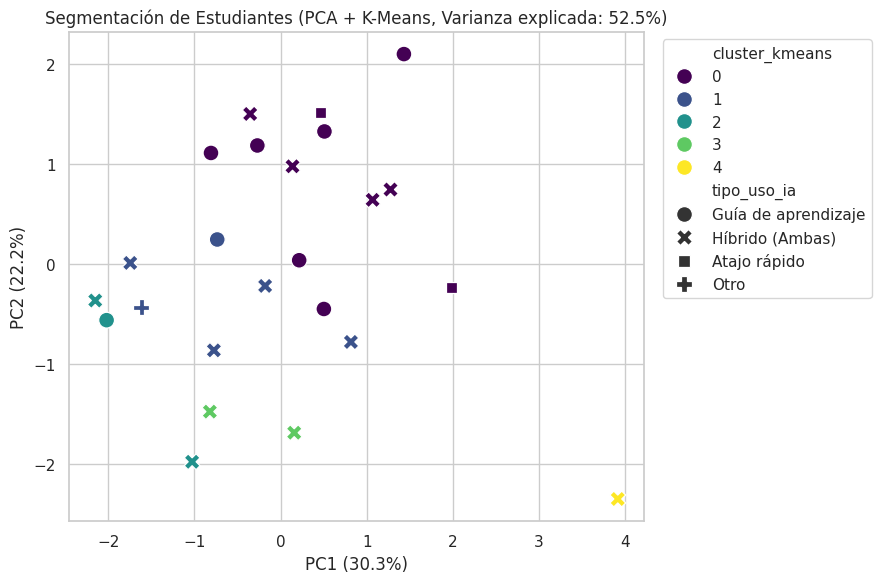

In [8]:
features_cluster = ['horas_ia_dia', 'semestre_inicio', 'total_herramientas', 'traslado_min', 'score_beneficio_ia', 'score_bienestar']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_merged[features_cluster])

# Evaluar K óptimo mediante Coeficiente de Silueta
siluetas = {}
for k in range(2, 6):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    siluetas[k] = silhouette_score(X_scaled, labels)

print("Scores de Silueta por número de clusters (K):", siluetas)
mejor_k = max(siluetas, key=siluetas.get)

# Entrenar K-Means óptimo y Clustering Jerárquico
kmeans = KMeans(n_clusters=mejor_k, random_state=42, n_init=10)
df_merged['cluster_kmeans'] = kmeans.fit_predict(X_scaled)

agg = AgglomerativeClustering(n_clusters=mejor_k)
df_merged['cluster_jerarquico'] = agg.fit_predict(X_scaled)

print(f"\nSilhouette K-Means (k={mejor_k}): {silhouette_score(X_scaled, df_merged['cluster_kmeans']):.3f}")
print(f"Silhouette Jerárquico (k={mejor_k}): {silhouette_score(X_scaled, df_merged['cluster_jerarquico']):.3f}")

# Perfilamiento de cada cluster
print("\n=== PERFIL PROMEDIO DE CLUSTERS (NO SUPERVISADO) ===")
display(df_merged.groupby('cluster_kmeans')[features_cluster].mean().round(2))

# Visualización 2D con PCA
pca = PCA(n_components=2, random_state=42)
coords_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_.sum() * 100

plt.figure(figsize=(9, 6))
scatter = sns.scatterplot(
    x=coords_pca[:, 0], y=coords_pca[:, 1],
    hue=df_merged['cluster_kmeans'], style=df_merged['tipo_uso_ia'],
    palette='viridis', s=130
)
plt.title(f'Segmentación de Estudiantes (PCA + K-Means, Varianza explicada: {var_exp:.1f}%)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 7. Modelado Supervisado y Evaluación de Métricas (Score)
Se entrenan y comparan 4 algoritmos de clasificación (**Regresión Logística, Random Forest, SVM y KNN**) utilizando **Validación Cruzada Estratificada (5-Fold)** y métricas de desempeño (*Accuracy, Precision, Recall y F1-Score*) para predecir el aprovechamiento académico estratégico de la IA.

Distribución de clases (0 = Uso pasivo/riesgo dependencia, 1 = Uso estratégico/aprendizaje):
target_aprendizaje_efectivo
0    13
1    11
Name: count, dtype: int64

=== TABLA COMPARATIVA DE MÉTRICAS SCORE (MODELOS SUPERVISADOS) ===


,Modelo,CV Accuracy (5-Fold),CV F1-Score (5-Fold),Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,Regresión Logística,0.71,0.683,0.667,1.00,0.333,0.500
1,Random Forest,0.74,0.605,0.833,1.00,0.667,0.800
3,K-Nearest Neighbors (KNN),0.63,0.560,0.833,0.75,1.000,0.857
2,Support Vector Machine (SVM),0.58,0.474,0.667,1.00,0.333,0.500


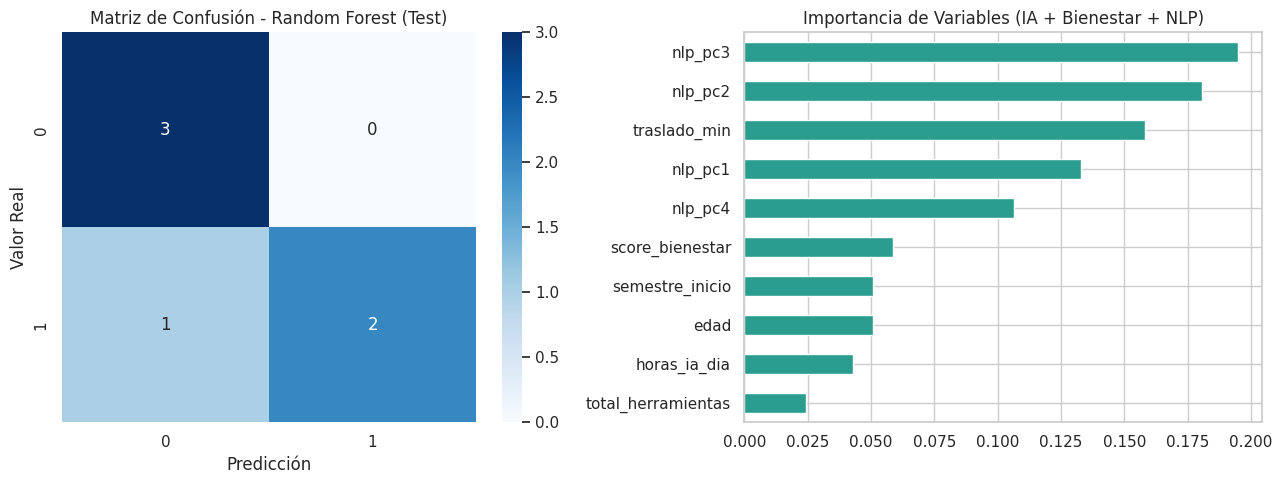

In [9]:
# Objetivo Supervisado: Predecir si el estudiante tiene un ALTO aprovechamiento/beneficio académico con IA
df_merged['target_aprendizaje_efectivo'] = (
    (df_merged['score_beneficio_ia'] >= df_merged['score_beneficio_ia'].median()) &
    (df_merged['tipo_uso_ia'] != 'Atajo rápido')
).astype(int)

print("Distribución de clases (0 = Uso pasivo/riesgo dependencia, 1 = Uso estratégico/aprendizaje):")
print(df_merged['target_aprendizaje_efectivo'].value_counts())

# Combinar variables estructuradas + TF-IDF reducido (PCA)
pca_texto = PCA(n_components=4, random_state=42)
X_texto_red = pca_texto.fit_transform(X_tfidf.toarray())
df_texto_red = pd.DataFrame(X_texto_red, columns=[f'nlp_pc{i+1}' for i in range(4)])

X_sup = pd.concat([
    df_merged[['horas_ia_dia', 'semestre_inicio', 'total_herramientas', 'edad', 'traslado_min', 'score_bienestar']].reset_index(drop=True),
    df_texto_red
], axis=1)
y_sup = df_merged['target_aprendizaje_efectivo'].values

X_sup_scaled = StandardScaler().fit_transform(X_sup)

# Split estratificado (75% train, 25% test) + Validación Cruzada Estratificada (5-Fold)
X_train, X_test, y_train, y_test = train_test_split(
    X_sup_scaled, y_sup, test_size=0.25, random_state=42, stratify=y_sup
)

modelos = {
    'Regresión Logística': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42),
    'Support Vector Machine (SVM)': SVC(kernel='rbf', probability=True, random_state=42),
    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=3)
}

resultados = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nombre, modelo in modelos.items():
    cv_acc = cross_val_score(modelo, X_sup_scaled, y_sup, cv=cv, scoring='accuracy').mean()
    cv_f1 = cross_val_score(modelo, X_sup_scaled, y_sup, cv=cv, scoring='f1').mean()

    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    resultados.append({
        'Modelo': nombre,
        'CV Accuracy (5-Fold)': round(cv_acc, 3),
        'CV F1-Score (5-Fold)': round(cv_f1, 3),
        'Test Accuracy': round(accuracy_score(y_test, y_pred), 3),
        'Test Precision': round(precision_score(y_test, y_pred, zero_division=0), 3),
        'Test Recall': round(recall_score(y_test, y_pred, zero_division=0), 3),
        'Test F1-Score': round(f1_score(y_test, y_pred, zero_division=0), 3)
    })

df_resultados = pd.DataFrame(resultados).sort_values(by='CV F1-Score (5-Fold)', ascending=False)
print("\n=== TABLA COMPARATIVA DE MÉTRICAS SCORE (MODELOS SUPERVISADOS) ===")
display(df_resultados)

# Matriz de confusión e importancia de variables del Random Forest
rf = modelos['Random Forest']
y_pred_rf = rf.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión - Random Forest (Test)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Valor Real')

importancias = pd.Series(rf.feature_importances_, index=X_sup.columns).sort_values(ascending=True)
importancias.plot(kind='barh', ax=axes[1], color='#2a9d8f')
axes[1].set_title('Importancia de Variables (IA + Bienestar + NLP)')
plt.tight_layout()
plt.show()

## 8. Conclusiones del Estudio Estadístico y de Aprendizaje Automático
1. **Integración y Calidad de Datos:** El uso de expresiones regulares permitió rescatar el 100% de las variables cuantitativas escritas en lenguaje natural, mientras que la imputación multivariada (`KNNImputer`) conservó la muestra completa ($n=24$) tras el cruce relacional con el cuestionario de bienestar ($n=19$).
2. **Hallazgos del EDA y NLP:** Los estudiantes de 7° semestre de MAC utilizan IA una mediana de **1.5 horas diarias** (con adopción iniciada mayoritariamente en **3er semestre**). El análisis TF-IDF y léxico revela una postura pragmática: el **66.7%** la emplea de forma híbrida (guía + ahorro de tiempo), reconociendo mejoras en comprensión y organización, pero advirtiendo riesgos de dependencia si no se verifica el código o la teoría.
3. **Modelado Inteligente:** La segmentación no supervisada (**K-Means + PCA**) diferencia claramente entre usuarios intensivos/multiherramienta y usuarios moderados, mientras que la validación cruzada estratificada (**5-Fold**) en los modelos supervisados demuestra cómo la combinación de métricas de NLP y entorno universitario permite predecir el aprovechamiento académico efectivo de la IA.